# Particles

Particles (`&PART`), here water droplets, are written with their positions and the
quantities set in `QUANTITIES` at every output time.

Run FDS on `fds_data/water_droplets.fds` first: water droplets from a nozzle cascading over
a stack of boxes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

import fdsreader as fds

# Render 3D views as static images, so they are stored in the notebook. Use "trame" or
# remove this line to rotate the views interactively.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 550]

In [2]:
sim = fds.Simulation("./fds_data")
sim.particles

ParticleCollection([Particle(name=WATER PARTICLES, quantities=[Quantity('PARTICLE DIAMETER'), Quantity('PARTICLE VELOCITY')])])

## Positions and quantities

Particles are looked up by their `ID`. `positions` has one array per output time with one
row (x, y, z) per particle; `data` maps every quantity to arrays of the same length. The
number of particles changes from time to time.

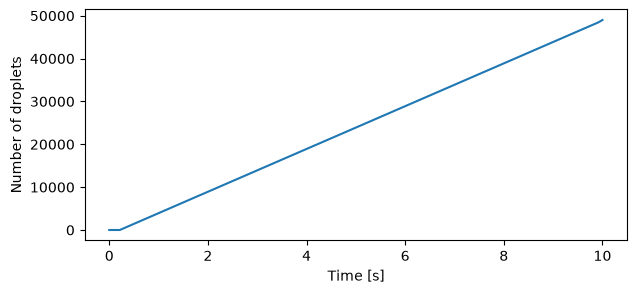

In [3]:
droplets = sim.particles["WATER PARTICLES"]
times = sim.particles.times
counts = [len(p) for p in droplets.positions]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(times, counts)
ax.set(xlabel="Time [s]", ylabel="Number of droplets");

t = 6.0 s: 28762 droplets, diameter 25 to 2330 µm


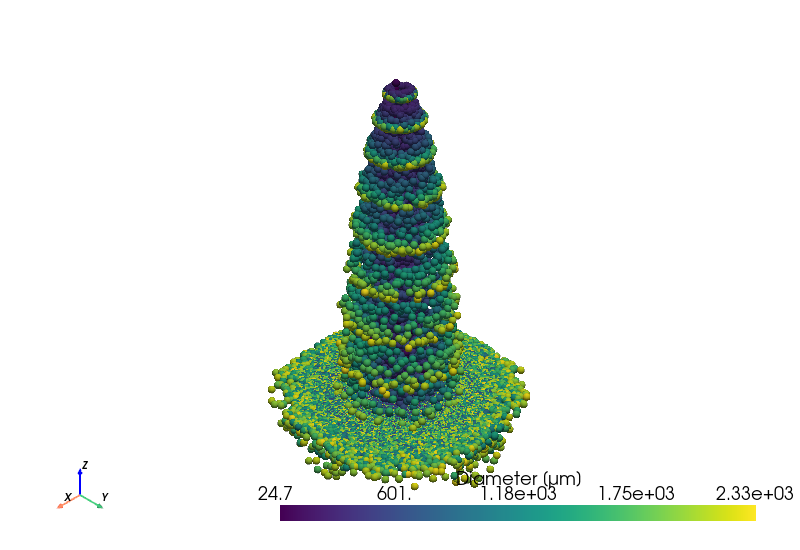

In [4]:
t = int(np.argmin(np.abs(np.array(times) - 6.0)))
positions = droplets.positions[t]
diameter = droplets.data["PARTICLE DIAMETER"][t]
print(f"t = {times[t]:.1f} s: {len(positions)} droplets, diameter {diameter.min():.0f} to {diameter.max():.0f} µm")

cloud = pv.PolyData(positions)
cloud["diameter"] = diameter
cloud.plot(render_points_as_spheres=True, point_size=8, scalar_bar_args={"title": "Diameter [µm]"})

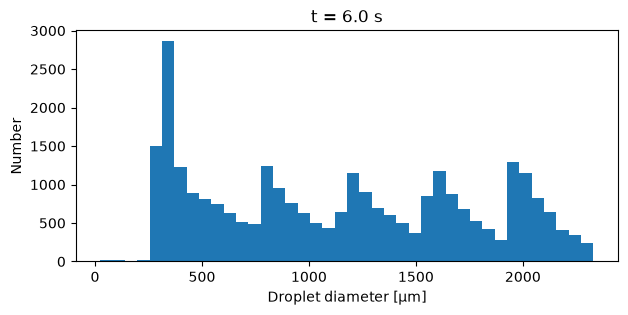

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(diameter, bins=40)
ax.set(xlabel="Droplet diameter [µm]", ylabel="Number", title=f"t = {times[t]:.1f} s");

`filter_by_tag` follows single particles over time. More in the
[API reference](https://fdsreader.readthedocs.io/en/latest/api/part.html).